# От пустой витрины до оплаты в VK
**VK CaseChamp 2026 · сентябрь · аналитика команды**

Из 7 319 товарных сообществ 288 получили заказ через чекаут. В масштабах Маркета внутри VK оплатили 4 903 из 413 740 оформленных заказов. Первый показатель характеризует продавцов, второй — заказы площадки.

Четыре графика показывают, на каком этапе предложенные командой инструменты могут помочь продавцу или покупателю. Для повторного запуска положите исходную книгу организаторов в `data/Датасет.xlsx` или укажите путь в следующей ячейке.

### Импорты

In [1]:
from pathlib import Path
import base64
import json

import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
import kaleido

### Оформление графиков

In [2]:
VK_BLUE = '#0077FF'
ORANGE = '#FF8A00'
PINK = '#EB4665'
PALE_PINK = '#F5A1B2'
GREY = '#C4CDD7'
INK = '#17212B'
SOURCE = Path('data/Датасет.xlsx')
EXPORT_PNG = True

### Функция вывода графика

In [3]:
def show_chart(fig, title, filename, left=60):
    fig.update_layout(
        template='simple_white', paper_bgcolor='white', plot_bgcolor='white',
        width=1000, height=555, font=dict(family='Arial', size=19, color=INK),
        title=dict(text='<b>' + title + '</b>', x=0.025, xanchor='left', y=.96, font_size=31),
        margin=dict(t=135, b=90, l=left, r=35), bargap=.38, separators=', ',
    )
    fig.update_xaxes(showgrid=False, ticks='', zeroline=False)
    fig.update_yaxes(showgrid=False, ticks='', zeroline=False)
    bundle = {'application/vnd.plotly.v1+json': json.loads(fig.to_json())}
    if EXPORT_PNG:
        png = kaleido.calc_fig_sync(fig, opts={'format': 'png', 'scale': 1.6},
                                    kopts={'page_generator': kaleido.PageGenerator(mathjax=False)})
        folder = Path('charts')
        folder.mkdir(exist_ok=True)
        (folder / filename).write_bytes(png)
        bundle['image/png'] = base64.b64encode(png).decode('ascii')
    display(bundle, raw=True)

In [4]:
def column_chart(labels, values, colors, digits=1, unit='%'):
    values = list(values)
    text = [f'<b>{v:.{digits}f}{unit}</b>'.replace('.', ',') for v in values]
    fig = go.Figure(go.Bar(x=list(labels), y=values, marker_color=colors, text=text,
                           textposition='outside', textfont=dict(size=25, color=INK),
                           cliponaxis=False, hovertemplate='%{x}<br>%{text}<extra></extra>'))
    fig.update_xaxes(showline=True, linecolor=INK, type='category')
    fig.update_yaxes(visible=False, range=[0, max(values) * 1.35])
    return fig

### Чтение данных организаторов

In [5]:
with pd.ExcelFile(SOURCE) as workbook:
    businesses = pd.read_excel(workbook, sheet_name='Бизнесы')
    monthly = pd.read_excel(workbook, sheet_name='Маркет Вконтакте — итоги').set_index('Метрика')
    daily = pd.read_excel(workbook, sheet_name='Маркет Вконтакте — по дням', parse_dates=['Дата'])

### Товарная выборка

In [6]:
orders = 'Заказы через чекаут'
catalog = 'Число активных товаров в каталоге'
spend = 'Траты на рекламу всего, ₽'
goods = businesses.loc[businesses['Тип бизнеса (товары / услуги)'].ne('услужное')]
invalid = goods[orders].gt(0) & goods['GMV через чекаут, ₽'].eq(0)
sample = goods.loc[~invalid].copy()
sample['Есть заказ'] = sample[orders].gt(0)
print(f'Сообществ в выгрузке: {len(businesses)}. Только услуги: {len(businesses)-len(goods)}.')
print(f'Исключены заказы при нулевом GMV: {invalid.sum()}.')
print(f'С заказом через чекаут: {sample["Есть заказ"].sum()} из {len(sample)} ({sample["Есть заказ"].mean():.1%}).')

Сообществ в выгрузке: 9754. Только услуги: 2428.
Исключены заказы при нулевом GMV: 7.
С заказом через чекаут: 288 из 7319 (3.9%).


## 1. Путь покупателя

Первые два шага сопоставляют открытия с показами и нажатия с открытиями. На третьем шаге знаменатель — оформленные заказы. Оплаты партнёра в выгрузке не указаны.

In [7]:
channels = ['Маркет Вконтакте', 'Партнёр 1']
opens = monthly.loc['Открытия карточки товара', channels].astype(float)
rates = pd.DataFrame({
    'Открытия / показы': 100 * opens / monthly.loc['Показы товаров', channels].astype(float),
    'Нажатия / открытия': 100 * monthly.loc['Нажатия на кнопку в карточке', channels].astype(float) / opens,
})
paid = monthly.at['Оплаченные заказы', channels[0]]
placed = monthly.at['Оформленные заказы', channels[0]]
rates['Оплата внутри VK'] = [100 * paid / placed, float('nan')]

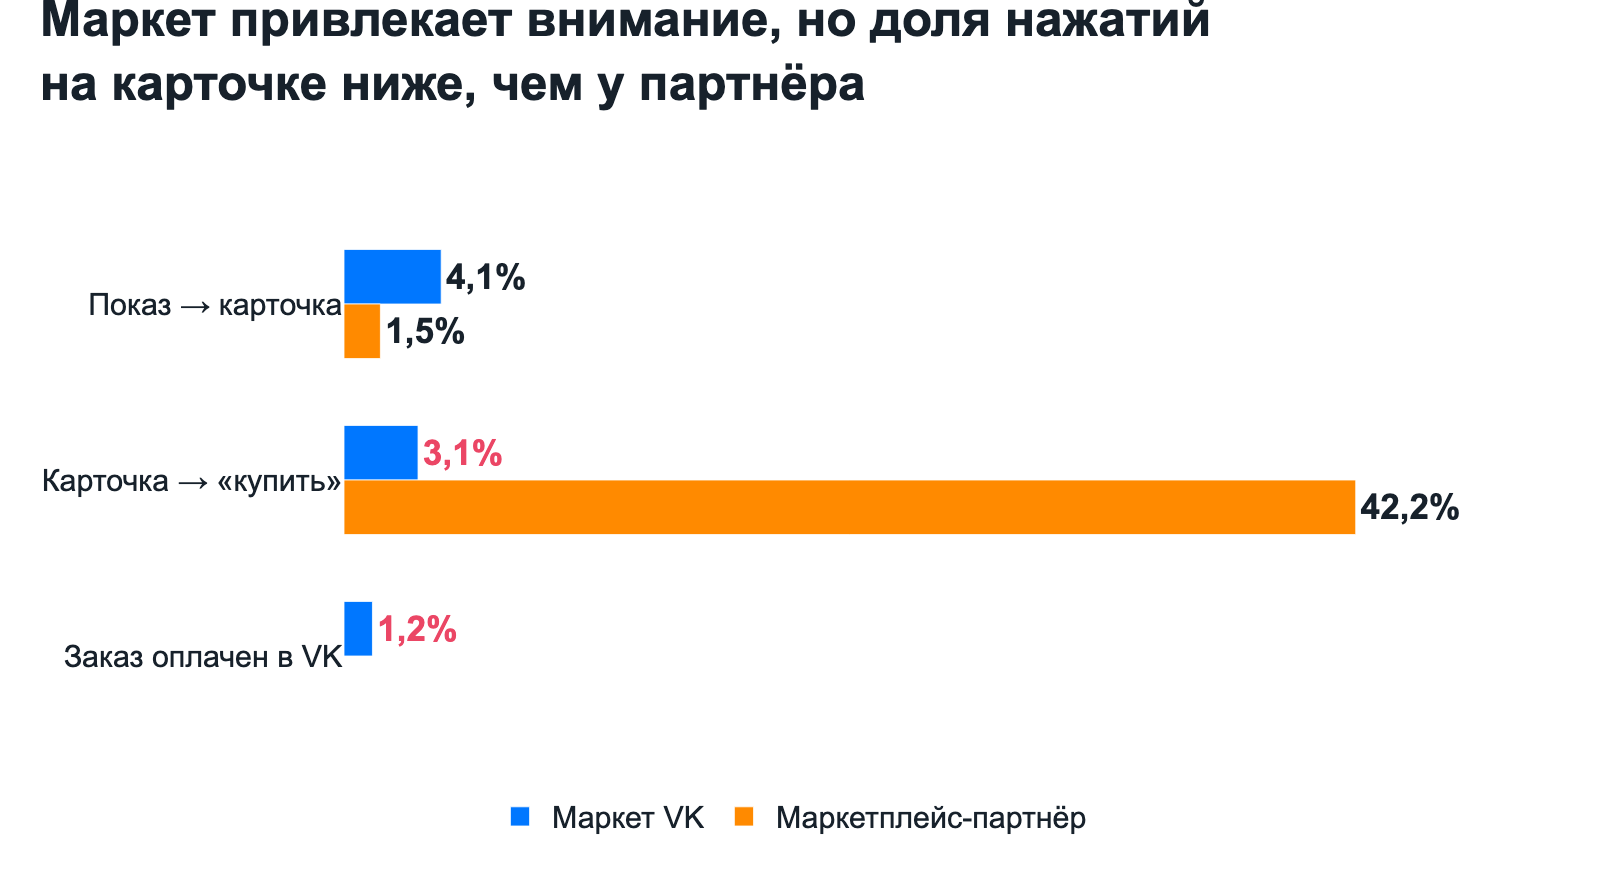

In [8]:
fig = go.Figure()
labels = ['Показ → карточка', 'Карточка → «купить»', 'Заказ оплачен в VK']
for i, (channel, name, color) in enumerate(zip(channels, ['Маркет VK','Маркетплейс-партнёр'], [VK_BLUE, ORANGE])):
    values = rates.loc[channel].dropna()
    fig.add_bar(name=name, x=values.tolist(), y=labels[:len(values)], orientation='h',
                marker_color=color, text=[f'<b>{v:.1f}%</b>'.replace('.', ',') for v in values],
                textfont=dict(size=22, color=[INK,PINK,PINK] if i==0 else INK),
                textposition='outside', hovertemplate='%{y} · %{text}<extra>%{fullData.name}</extra>')
fig.update_layout(barmode='group', legend=dict(orientation='h', x=.12, y=-.08))
fig.update_yaxes(autorange='reversed', showline=False)
fig.update_xaxes(visible=False, range=[0,50])
show_chart(fig, 'Маркет привлекает внимание, но доля нажатий<br>на карточке ниже, чем у партнёра', '1_путь_покупателя.png', left=215)

### Оплата внутри VK и динамика заказов

In [9]:
market = channels[0]
paid = monthly.at['Оплаченные заказы', market]
placed = monthly.at['Оформленные заказы', market]
print(f'Оплачено внутри VK: {paid:,} из {placed:,} оформленных заказов ({paid/placed:.2%}).')
days = daily.set_index('Дата').sort_index()
columns = [f'Заказы: {c}' for c in channels]
weeks = [days.loc[start:end, columns] for start, end in
         [('2026-09-01', '2026-09-07'), ('2026-09-24', '2026-09-30')]]
assert all(len(w) == w.index.nunique() == 7 for w in weeks)
totals = pd.DataFrame({'1–7 сентября': weeks[0].sum(), '24–30 сентября': weeks[1].sum()})
totals['Изменение, %'] = (totals.iloc[:, 1] / totals.iloc[:, 0] - 1) * 100
display(totals.round(1))

Оплачено внутри VK: 4,903 из 413,740 оформленных заказов (1.19%).


,1–7 сентября,24–30 сентября,"Изменение, %"
Заказы: Маркет Вконтакте,103415,92393,-10.7
Заказы: Партнёр 1,1119795,1321119,18.0


**Решение команды.** Проверить сценарий покупки на карточке и начислять Пейсы за подтверждённую оплату через VK Pay. В пилоте отслеживать долю оплаченных заказов и комиссию за вычетом стоимости наград. Ставка 3% — условие финансовой модели команды. Для расчёта дохода в рублях требуется сумма фактических оплат.

## 2. Какая часть рекламного бюджета приходится на магазины без заказа?

Суммируем поле «Траты на рекламу всего, ₽» внутри товарной выборки. Знаменатель — общие расходы всех 7 319 сообществ. Крупные бюджеты сохранены в исходном размере.

In [10]:
groups = pd.Series('Есть каталог и чекаут,<br>заказов нет', index=sample.index)
groups.loc[sample[catalog].eq(0) | sample['Подключён чекаут'].eq(0)] = 'Нет каталога<br>или чекаута'
groups.loc[sample['Есть заказ']] = 'Продают<br>через чекаут'
budgets = sample.groupby(groups)[spend].sum().reindex([
    'Нет каталога<br>или чекаута', 'Есть каталог и чекаут,<br>заказов нет', 'Продают<br>через чекаут'])
budget_share = budgets / budgets.sum() * 100
display(pd.DataFrame({'Расходы, ₽': budgets, 'Доля, %': budget_share.round(2)}))

,"Расходы, ₽","Доля, %"
Нет каталога<br>или чекаута,27610952,34.67
"Есть каталог и чекаут,<br>заказов нет",40603138,50.99
Продают<br>через чекаут,11418152,14.34


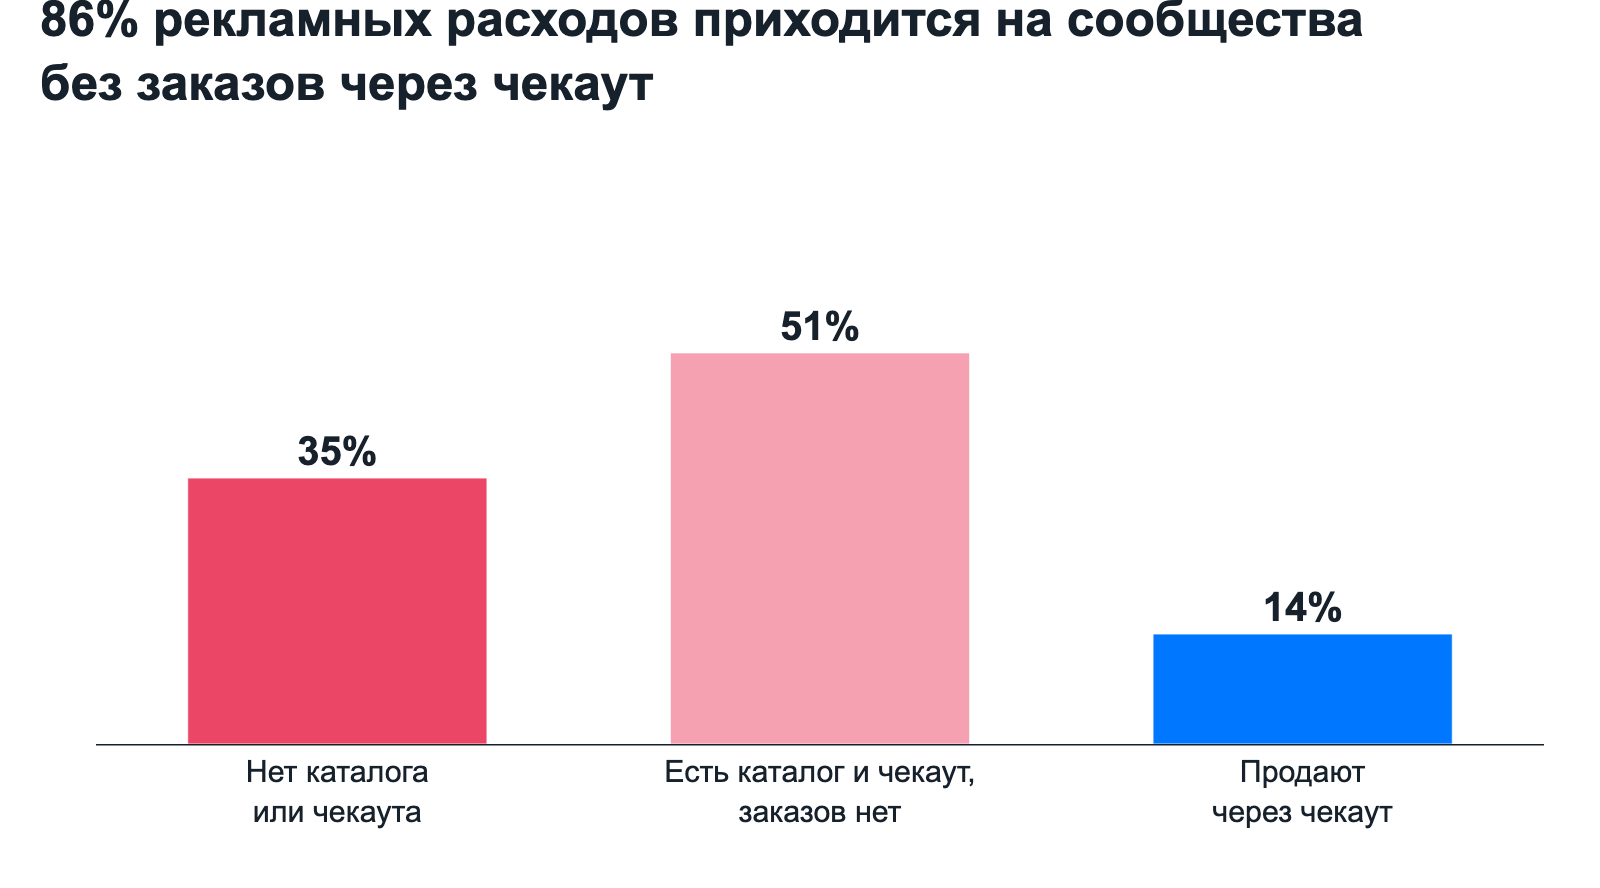

In [11]:
fig = column_chart(budget_share.index, budget_share, [PINK, PALE_PINK, VK_BLUE], digits=0)
show_chart(fig, '86% рекламных расходов приходится на сообщества<br>без заказов через чекаут', '2_рекламные_траты.png')

**Решение команды.** В едином кабинете рекламы и магазина перед запуском кампании на покупку проверять каталог и чекаут. Цель кампаний и период накопления расходов неизвестны. Покупки через сообщения и внешние сайты находятся за пределами наблюдения. Результат пилота можно оценить по стоимости оплаченного заказа.

## 3. Размер каталога и продажи

Сравниваем долю сообществ с заказом по числу активных товаров. Группа 100+ включает магазины ровно со 100 товарами.

In [12]:
bands = pd.cut(sample[catalog], [0, 5, 20, 99, float('inf')], labels=['1–5', '6–20', '21–99', '100+'])
catalog_stats = sample.groupby(bands, observed=True)['Есть заказ'].agg(продают='sum', всего='size')
catalog_stats['доля'] = catalog_stats['продают'] / catalog_stats['всего'] * 100
empty = sample[catalog].eq(0)
print(f'Без активных товаров: {empty.sum()} из {len(sample)} ({empty.mean():.1%}).')
print(f'Отношение долей 100+ к 1–5: {catalog_stats.loc["100+", "доля"]/catalog_stats.loc["1–5", "доля"]:.1f} раза.')

Без активных товаров: 3364 из 7319 (46.0%).
Отношение долей 100+ к 1–5: 13.1 раза.


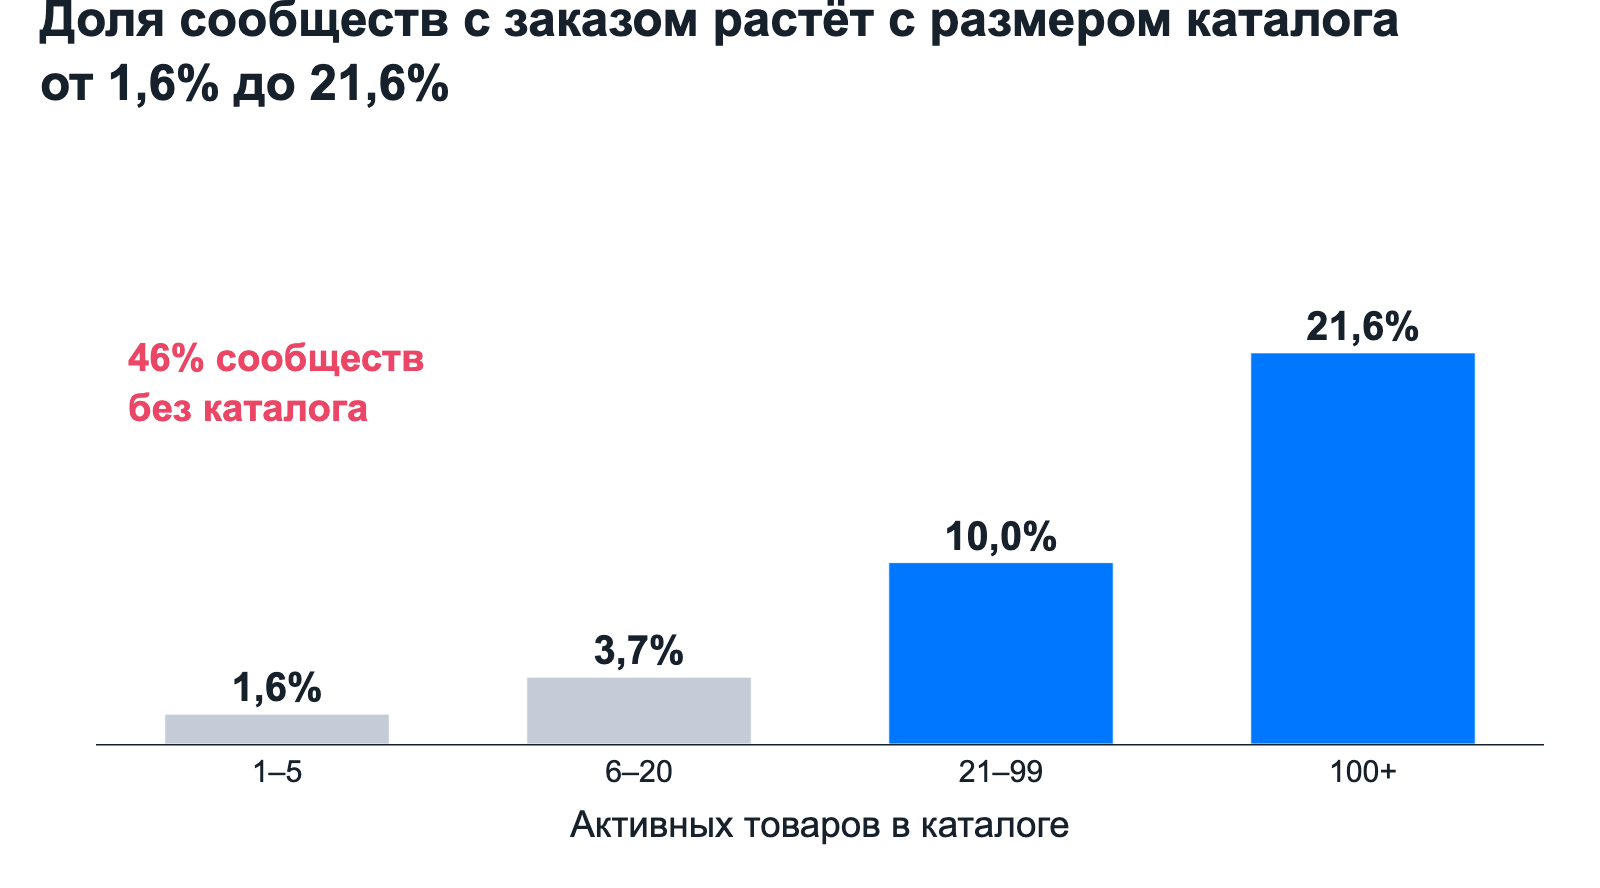

In [13]:
fig = column_chart(catalog_stats.index, catalog_stats['доля'], [GREY, GREY, VK_BLUE, VK_BLUE])
fig.update_xaxes(title='Активных товаров в каталоге')
fig.add_annotation(xref='paper', yref='paper', x=.02, y=.78, xanchor='left', showarrow=False,
                   text=f'<b>{empty.mean():.0%} сообществ<br>без каталога</b>', align='left', font=dict(color=PINK,size=24))
show_chart(fig, 'Доля сообществ с заказом растёт с размером каталога<br>от 1,6% до 21,6%', '3_каталог_и_продажи.png')

**Решение команды.** Заполнять карточку по фото и предлагать ключевые фразы, чтобы продавец быстрее опубликовал ассортимент. Разница между группами может отражать опыт продавца и размер аудитории. Для проверки эффекта сравнить время до публикации и долю магазинов с первым заказом за 30 дней в пилотной и контрольной группах.

## 4. Сценарии комиссии VK Pay

При фиксированном сентябрьском GMV комиссия равна обороту Маркета × доле GMV через VK Pay × 3%. Для текущей оценки предполагаем одинаковый средний чек у оплаченных и остальных заказов. Фактическая сумма оплат в выгрузке отсутствует.

In [14]:
gmv = monthly.at['GMV, ₽', channels[0]]
fee_rate = .03  # условие модели команды
turnover_share = pd.Series([paid/placed, .10, .25, .50], index=['Сейчас<br>(оценка)', '10%', '25%', '50%'])
commission = gmv * turnover_share * fee_rate / 1e6
print(f'GMV Маркета за сентябрь: {gmv:,.0f} ₽.')

GMV Маркета за сентябрь: 1,564,546,740 ₽.


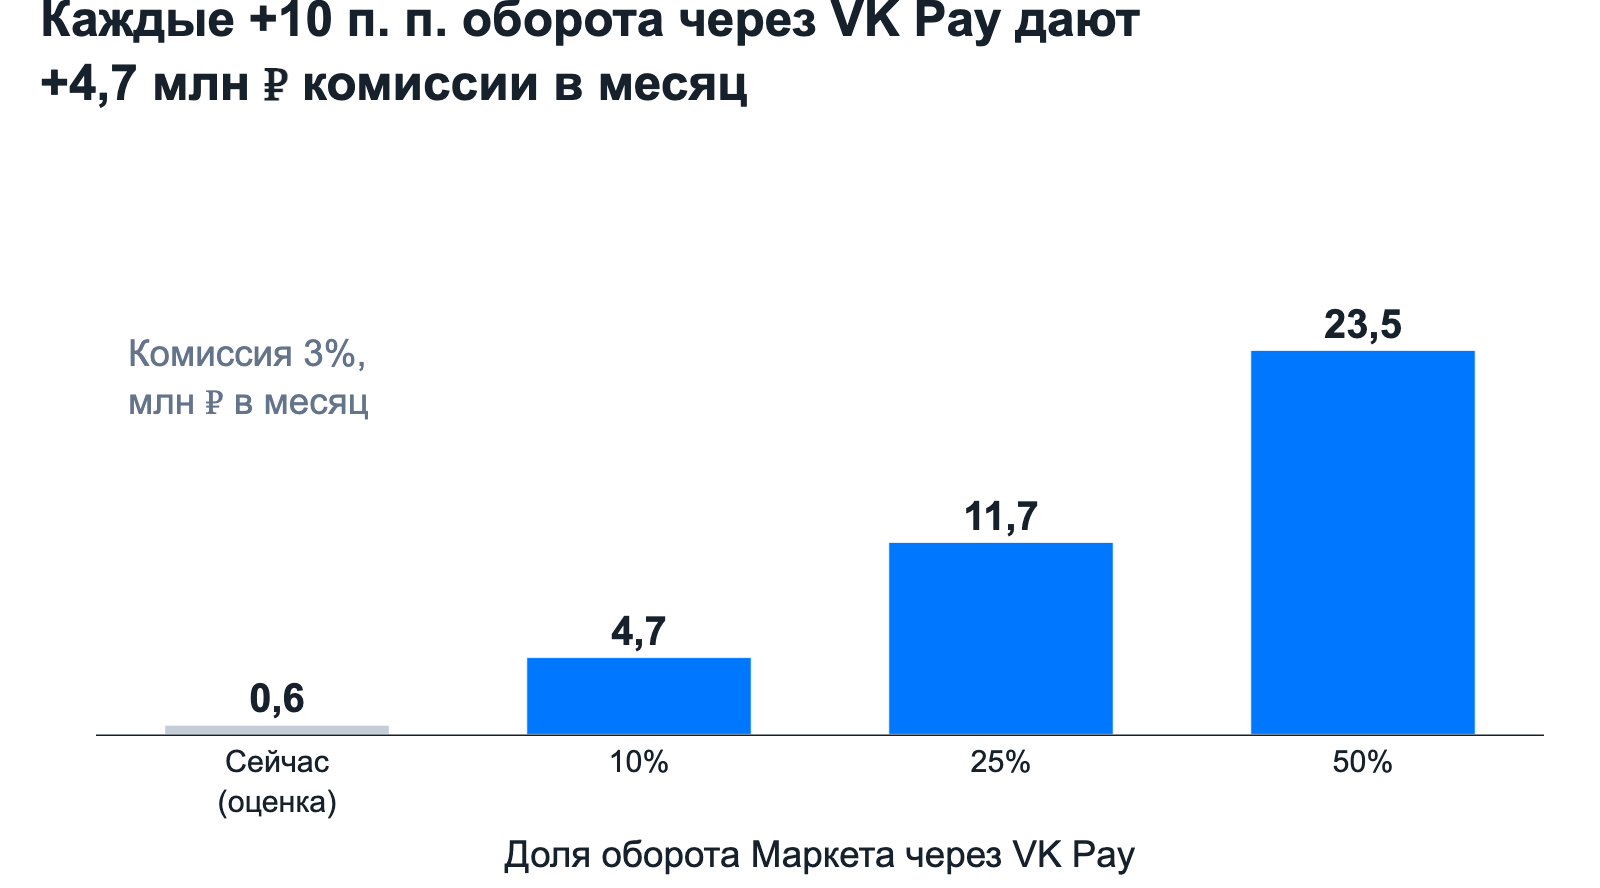

In [15]:
fig = column_chart(commission.index, commission, [GREY, VK_BLUE, VK_BLUE, VK_BLUE], unit='')
fig.update_xaxes(title='Доля оборота Маркета через VK Pay')
fig.add_annotation(xref='paper', yref='paper', x=.02, y=.78, xanchor='left', showarrow=False,
                   text='Комиссия 3%,<br>млн ₽ в месяц', align='left', font=dict(color='#64748B',size=23))
show_chart(fig, 'Каждые +10 п. п. оборота через VK Pay дают<br>+4,7 млн ₽ комиссии в месяц', '4_комиссия_VK_Pay.png')